## Part 2: Stimuli

Now what we want to do is plot the predicted v the observed and the correlation.

We will do all preferred stimuli and then non-preferred stimuli in the same plot

In [13]:
%load_ext autoreload
%autoreload 2

# standard imports
import os
import numpy as np
from sklearn.linear_model import Ridge
import torch
import re
from sklearn.model_selection import StratifiedKFold
import scipy
from tqdm.notebook import tqdm
import pandas as pd
import warnings
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# custom imports

from compcats.models import resnet50_openaiclip
from compcats.datasets.fmri import murty185
from compcats.utils import model_utils, misc_utils, responsecomparison_utils
from compcats.encoder import encode

MODELS_DIR = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)
MURTY185_DIR = 'datasets/murty185'
FMRI_DIR = 'fmri_data'
RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ImportWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)
warnings.filterwarnings("ignore", category=Warning)  # catch-all for any base warnings
warnings.filterwarnings("ignore")

In [3]:
model = resnet50_openaiclip.get_model()
layers = model.relevant_layer_names

In [4]:
pattern = r"layer[1-4]\.\d+\.conv\d+"

filtered_layers = []
for l in layers:
    if re.search(pattern,l):
        filtered_layers.append(l)

# at this point I only have the layers I care about

nr_layers = len(filtered_layers)

In [5]:
# to answer earlier question, yes I need a dataset class
# one more question about the save_dir - can I just create a folder that is pretrained_models/name of model? or what is the best way
# X = model.generate_dataset_activations(layers,dataset,save_dir,num_workers=4)
X = model_utils.get_dataset_activations(
    MODELS_DIR, MURTY185_DIR, model, filtered_layers, 'murty185', device='cpu'
)
for key, value in X.items():
    X[key] = value.flatten(start_dim=1)

In [6]:
categories = murty185.LABELS
categories = np.array(categories)

In [7]:
all_files = os.listdir(FMRI_DIR)
Y_all = {} # Y_all['group']['nr as int']['froi']
frois_considered = ['lffa', 'rffa', 'leba', 'reba']
for f in all_files:
    subnum, froi, _ = f.split('.')[0].split('_')
    if froi not in frois_considered:
        continue
    subnum = subnum.replace('sub-', '')
    subtype = subnum[:2]
    subnum = int(subnum[2:])
    if subtype not in Y_all.keys():
        Y_all[subtype] = {}
    if froi not in Y_all[subtype]:
        Y_all[subtype][froi] = {}
    Y_all[subtype][froi][subnum] = torch.load(f'{FMRI_DIR}/{f}').cpu().numpy()
for subtype, subtypedata in Y_all.items():
    for froi in frois_considered:
        Y_all[subtype][froi] = dict(sorted(subtypedata[froi].items()))

subject_numbers_dict = {} # subject type -> [subject number]
for subtype, subtypedata in Y_all.items():
    subject_numbers_dict[subtype] = list(subtypedata[frois_considered[0]].keys())

In [8]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # 5fold; default seed is 42

In [9]:
prior_results_csv_name = 'ccn_pt1.csv'

df_prior_results = pd.read_csv(f'{RESULTS_DIR}/{prior_results_csv_name}')

In [ ]:
csv_name = 'ccn_pt2_stimuli_responses.csv'
csv_path = f'{RESULTS_DIR}/{csv_name}'
csv_rows_list = None
if os.path.exists(csv_path):
    csv_loaded = pd.read_csv(csv_path)
    csv_rows_list = csv_loaded.to_dict('records')
else:
    csv_rows_list = []

subtypes = ['nt','dp']

#frois_considered = ['lffa','leba']

for subtype in subtypes:
    print(f'Starting with group {subtype}')

    for froi in frois_considered:
        print(f'Processing roi: {froi}')

        y_dict = Y_all[subtype][froi]
        y_array = np.stack(list(y_dict.values())) # [value for value in y_dict.values()]

        nr_subs = y_array.shape[0]
        nr_test_subs = nr_subs-1

        hold_test_rdmr = np.zeros([nr_subs,nr_layers,5])
        hold_test_pearsonr = np.zeros([nr_subs,nr_layers,5])

        hold_observed_responses = np.zeros([nr_subs,185,100]) 
        hold_predicted_responses = np.zeros([nr_subs,nr_test_subs,185,100])

        for tidx in np.arange(nr_subs):
            print(f'Processing subject idx {tidx}')
            test_subj_data =  y_array[tidx,:,:]
            y_array_cp = y_array.copy()
            all_train_subjects = np.array(subject_numbers_dict[subtype])
            current_train_subjects = np.delete(all_train_subjects,tidx,axis=0)
            train_subj_data = np.delete(y_array_cp,tidx,axis=0)

            #for lidx, layer_name in tqdm(enumerate(filtered_layers), total=len(filtered_layers)):

            hold_df_prior_results = df_prior_results[
                    (df_prior_results["subject_type"] == subtype) & 
                    (df_prior_results["froi"] == froi) &
                    (df_prior_results["test_subject"] == subject_numbers_dict[subtype][tidx])
            ]
            
            hold_best_metric = hold_df_prior_results.loc[
                hold_df_prior_results["mean_pearsonr"].idxmax(),
                ["froi","subject_type","test_subject", "layer", "mean_pearsonr"] 
            ]

            layer_name = hold_best_metric["layer"]

            X_layer = X[layer_name]

            #layer_split_pearsonr = []
            #layer_split_rdmr = []
            for spidx, (train_index, test_index) in enumerate(skf.split(X_layer, categories)):
                
                x_train_fold, x_test_fold = X_layer[train_index], X_layer[test_index]
                categories_train_fold, categories_test_fold = categories[train_index], categories[test_index]

                #X_trains.append(x_train_fold)
                #X_tests.append(x_test_fold)

                #categories_train_labels.append(categories_train_fold)
                #categories_test_labels.append(categories_test_fold)

                # get ready...

                test_responses = test_subj_data[test_index,:] 
                test_responses_mean = test_responses.mean(axis=-1)

                X_train = x_train_fold
                X_test = x_test_fold

                temp_test_pearsonr = []

                for tridx in np.arange(train_subj_data.shape[0]):
                    train_responses = train_subj_data[tridx,train_index,:]

                    row_params = {
                        'subject_type': subtype,
                        'froi': froi,
                        'test_subject': subject_numbers_dict[subtype][tidx],
                        'train_subject': current_train_subjects[tridx].item(),
                        'model': model.name,
                        'layer': layer_name,
                        'split_index': spidx
                    }
                    if misc_utils.check_row_present(row_params, csv_rows_list):
                        continue

                    # run fit_eval mapper and do your thing thing
                    em_mapper, train_rdmr, test_rdmr = encode.fit_eval_mapper(
                        Ridge(alpha=0.01),
                        X_train.cpu().numpy(),
                        train_responses,
                        X_test.cpu().numpy(),
                        test_responses,
                        metric='population_erdmr'
                    )
                    y_pred = em_mapper.predict(X_test.cpu().numpy()) # 37,100 (nimg,nvtx)

                    y_pred_mean = y_pred.mean(axis=-1)

                    test_pearsonr = scipy.stats.pearsonr(y_pred_mean, test_responses_mean)
                    test_pearsonr = test_pearsonr[0].item()       

                    for ciidx,current_img in enumerate(test_index):

                        # Save results
                        csv_rows_list.append({
                            **row_params,
                            'img_cat': categories_test_fold[ciidx], # category_label
                            'overall_img_idx': current_img,
                            'y_prediction': y_pred_mean[ciidx],
                            'y_observed': test_responses_mean[ciidx],
                            'test_pearsonr': test_pearsonr,
                            'test_rdmr': test_rdmr
                        })
                        results_csv = pd.DataFrame(csv_rows_list)
                        results_csv.to_csv(csv_path, index=False)

Starting with group nt
Processing roi: lffa
Processing subject idx 0
Processing subject idx 1
Processing subject idx 2
Processing subject idx 3
Processing subject idx 4
Processing subject idx 5
Processing subject idx 6
Processing roi: leba
Processing subject idx 0
Processing subject idx 1
Processing subject idx 2
Processing subject idx 3
Processing subject idx 4
Processing subject idx 5
Processing subject idx 6
Starting with group dp
Processing roi: lffa
Processing subject idx 0
Processing subject idx 1
Processing subject idx 2
Processing roi: leba
Processing subject idx 0
Processing subject idx 1
Processing subject idx 2


<Figure size 640x480 with 0 Axes>

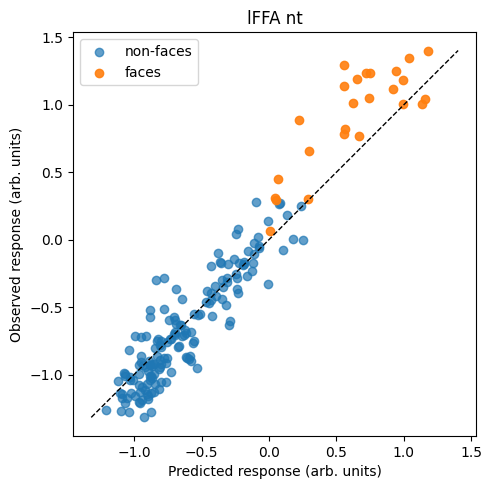

<Figure size 640x480 with 0 Axes>

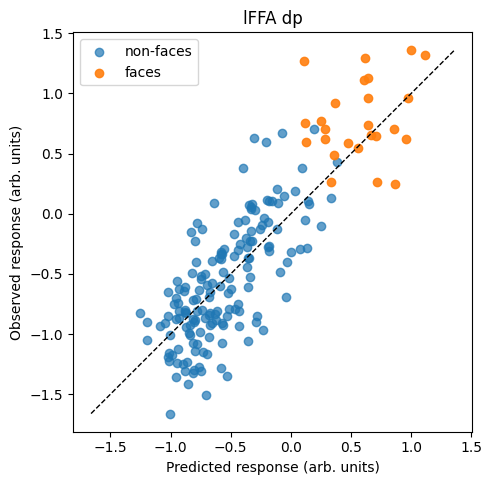

In [41]:
for subtype in subtypes:
    plt.figure()

    # --- filter to one ROI / model / layer ---
    df_sub = results_csv[
        (results_csv['froi'] == 'lffa') &
        (results_csv['subject_type']==subtype)
    ].copy()

    # --- Stage 1: average across train_subject ---
    df_stage1 = (
        df_sub
        .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
        .agg({
            'y_prediction': 'mean',
            'y_observed': 'mean'
        })
    )

    # --- Stage 2: average across test_subject ---
    df_final = (
        df_stage1
        .groupby(['overall_img_idx', 'img_cat'], as_index=False)
        .agg({
            'y_prediction': 'mean',
            'y_observed': 'mean'
        })
    )

    # --- plotting ---
    fig, ax = plt.subplots(figsize=(5, 5))

    # faces = blue, others = red
    mask_faces = df_final['img_cat'] == 'faces'

    ax.scatter(
        df_final.loc[~mask_faces, 'y_prediction'],
        df_final.loc[~mask_faces, 'y_observed'],
        alpha=0.7,
        label='non-faces'
    )

    ax.scatter(
        df_final.loc[mask_faces, 'y_prediction'],
        df_final.loc[mask_faces, 'y_observed'],
        alpha=0.9,
        label='faces'
    )

    # diagonal line
    lims = [
        min(df_final['y_prediction'].min(), df_final['y_observed'].min()),
        max(df_final['y_prediction'].max(), df_final['y_observed'].max())
    ]
    ax.plot(lims, lims, 'k--', linewidth=1)

    ax.set_xlabel('Predicted response (arb. units)')
    ax.set_ylabel('Observed response (arb. units)')
    ax.set_title('lFFA ' + subtype)

    ax.legend()
    ax.set_aspect('equal')

    plt.tight_layout()
    plt.show()

In [44]:
print(df_sub.groupby(['train_subject'])['y_prediction'].mean())

train_subject
1   -0.432401
3   -0.301745
6   -0.486539
Name: y_prediction, dtype: float64


In [45]:
print(df_sub.groupby(['train_subject'])['y_prediction'].std())

train_subject
1    0.568134
3    0.503419
6    0.549996
Name: y_prediction, dtype: float64


<Figure size 640x480 with 0 Axes>

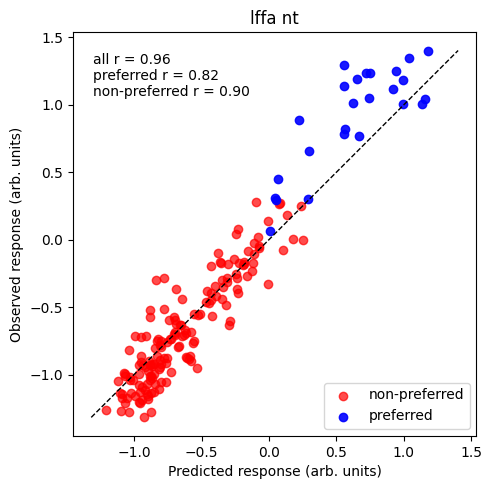

<Figure size 640x480 with 0 Axes>

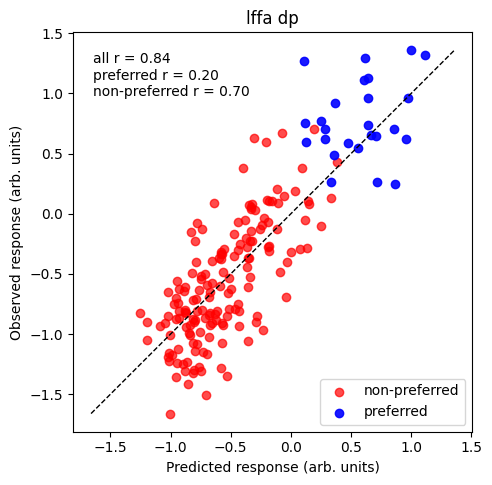

<Figure size 640x480 with 0 Axes>

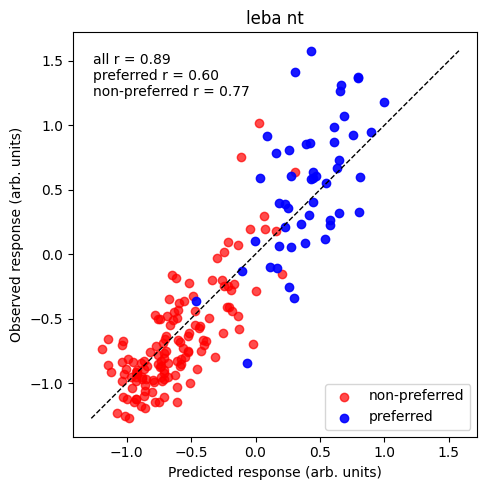

<Figure size 640x480 with 0 Axes>

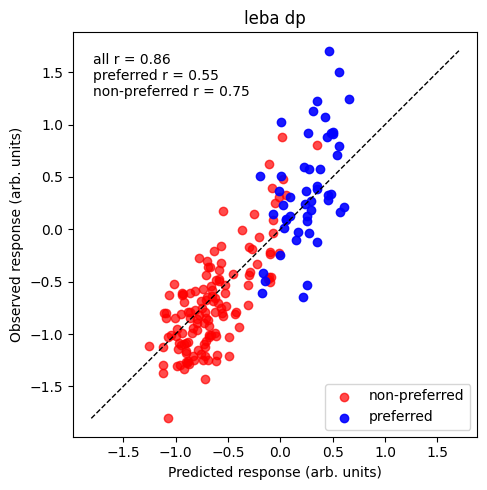

In [14]:
for froi in frois_considered:
    for subtype in subtypes:
        plt.figure()

        if 'ffa' in froi:
            preferred_stim = 'faces'
        elif 'eba' in froi:
            preferred_stim = 'bodies'        

        # --- filter to one ROI / model / layer ---
        df_sub = results_csv[
            (results_csv['froi'] == froi) &
            (results_csv['subject_type'] == subtype)
        ].copy()

        # --- Stage 1: average across train_subject ---
        df_stage1 = (
            df_sub
            .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
            .agg({
                'y_prediction': 'mean',
                'y_observed': 'mean'
            })
        )

        # --- Stage 2: average across test_subject ---
        df_final = (
            df_stage1
            .groupby(['overall_img_idx', 'img_cat'], as_index=False)
            .agg({
                'y_prediction': 'mean',
                'y_observed': 'mean'
            })
        )

        # --- masks ---
        mask_preferred = df_final['img_cat'] == preferred_stim
        mask_nonpreferred= ~mask_preferred

        # --- correlations ---
        r_preferred, _ = pearsonr(
            df_final.loc[mask_preferred, 'y_prediction'],
            df_final.loc[mask_preferred, 'y_observed']
        )

        r_nonpreferred, _ = pearsonr(
            df_final.loc[mask_nonpreferred, 'y_prediction'],
            df_final.loc[mask_nonpreferred, 'y_observed']
        )

        r_all, _ = pearsonr(
            df_final['y_prediction'],
            df_final['y_observed']
        )

        # --- plotting ---
        fig, ax = plt.subplots(figsize=(5, 5))

        # non-preferred (red)
        ax.scatter(
            df_final.loc[mask_nonpreferred, 'y_prediction'],
            df_final.loc[mask_nonpreferred, 'y_observed'],
            color='red',
            alpha=0.7,
            label='non-preferred'
        )

        # preferred (blue)
        ax.scatter(
            df_final.loc[mask_preferred, 'y_prediction'],
            df_final.loc[mask_preferred, 'y_observed'],
            color='blue',
            alpha=0.9,
            label='preferred'
        )

        # diagonal line
        lims = [
            min(df_final['y_prediction'].min(), df_final['y_observed'].min()),
            max(df_final['y_prediction'].max(), df_final['y_observed'].max())
        ]
        ax.plot(lims, lims, 'k--', linewidth=1)

        # labels
        ax.set_xlabel('Predicted response (arb. units)')
        ax.set_ylabel('Observed response (arb. units)')
        ax.set_title(froi + ' ' + subtype)

        # correlation text
        ax.text(
            0.05, 0.95,
            f'all r = {r_all:.2f}\npreferred r = {r_preferred:.2f}\nnon-preferred r = {r_nonpreferred:.2f}',
            transform=ax.transAxes,
            verticalalignment='top',
            fontsize=10,
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
        )

        ax.legend()
        ax.set_aspect('equal')

        plt.tight_layout()
        plt.show()

<Figure size 640x480 with 0 Axes>

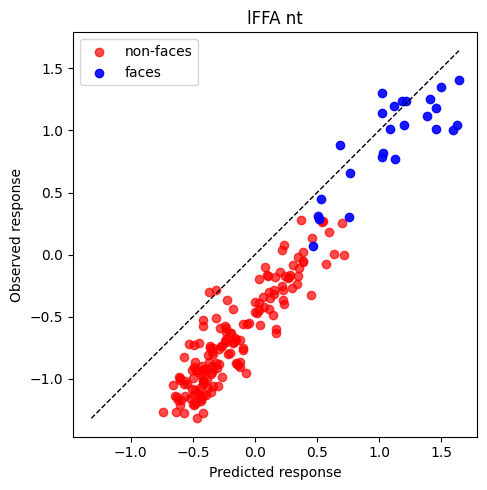

<Figure size 640x480 with 0 Axes>

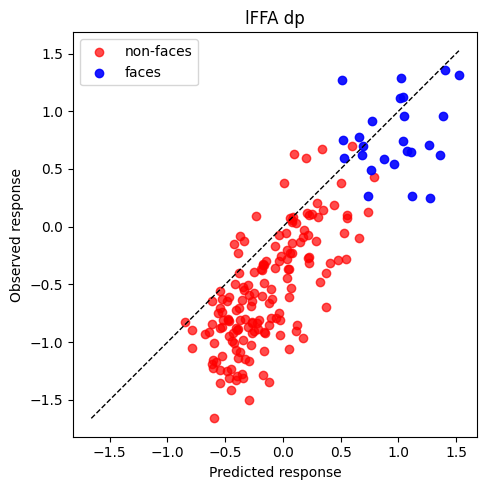

In [46]:
for subtype in subtypes:
    plt.figure()

    df_sub = results_csv[
        (results_csv['froi'] == 'lffa') &
        (results_csv['subject_type'] == subtype)
    ].copy()

    # center predictions within each train_subject x test_subject across images
    df_sub['y_prediction_centered'] = (
        df_sub
        .groupby(['train_subject', 'test_subject'])['y_prediction']
        .transform(lambda x: x - x.mean())
    )

    # Stage 1: average across train_subject
    df_stage1 = (
        df_sub
        .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
        .agg({
            'y_prediction_centered': 'mean',
            'y_observed': 'mean'
        })
    )

    # Stage 2: average across test_subject
    df_final = (
        df_stage1
        .groupby(['overall_img_idx', 'img_cat'], as_index=False)
        .agg({
            'y_prediction_centered': 'mean',
            'y_observed': 'mean'
        })
    )

    fig, ax = plt.subplots(figsize=(5, 5))

    mask_faces = df_final['img_cat'] == 'faces'

    ax.scatter(
        df_final.loc[~mask_faces, 'y_prediction_centered'],
        df_final.loc[~mask_faces, 'y_observed'],
        color='red',
        alpha=0.7,
        label='non-faces'
    )

    ax.scatter(
        df_final.loc[mask_faces, 'y_prediction_centered'],
        df_final.loc[mask_faces, 'y_observed'],
        color='blue',
        alpha=0.9,
        label='faces'
    )

    lims = [
        min(df_final['y_prediction_centered'].min(), df_final['y_observed'].min()),
        max(df_final['y_prediction_centered'].max(), df_final['y_observed'].max())
    ]
    ax.plot(lims, lims, 'k--', linewidth=1)

    ax.set_xlabel('Predicted response')
    ax.set_ylabel('Observed response')
    ax.set_title('lFFA ' + subtype)
    ax.legend()
    ax.set_aspect('equal')

    plt.tight_layout()
    plt.show()